# 01 · Bayesian optimization from scratch

**What you will learn.** How Bayesian optimization (BO) finds the maximum of an expensive black-box function with very few evaluations, by writing the whole loop yourself in about 25 lines, and then running OpenBO's own implementation on a standard 2D benchmark.

**The idea in one paragraph.** Suppose each evaluation of `f(x)` is costly (a lab experiment, a long simulation, a human rating) and you cannot afford thousands of them. BO keeps a cheap *surrogate model* of `f` (here a Gaussian process, GP) that is trained on the evaluations so far. The surrogate gives, for every candidate `x`, a prediction and an uncertainty. An *acquisition function* turns that into a score for how useful it would be to evaluate `x` next. You evaluate the best-scoring point, update the surrogate, and repeat.

```
repeat:
    1. fit a GP to all (x, y) observed so far
    2. score every candidate x with an acquisition function (here: expected improvement)
    3. evaluate f at the best-scoring x
```

**Conventions used throughout OpenBO**
- Every objective is **maximized**. A function you want to minimize is negated.
- Test functions take inputs in the unit cube `[0, 1]^d` and return one value per row.
- Regret is `log10(max(optimum - best_so_far, 1e-12))`: lower is better, and -3 means "within 0.001 of the optimum".

This notebook needs only NumPy and Matplotlib on top of OpenBO. It runs in about a minute.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from openbo.models.gp_scratch import GPScratch
from openbo.acquisition.ei import expected_improvement_maximization

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## 1. An expensive black box (here: a cheap 1D toy)

We use a one-dimensional function with two competing peaks so that we can *see* what the optimizer is thinking. The optimizer never sees the formula, only the values it asks for. The global maximum is at `x ≈ 0.77`; the lower peak near `x ≈ 0.27` is a trap for greedy search.

true maximum 1.020 at x = 0.768


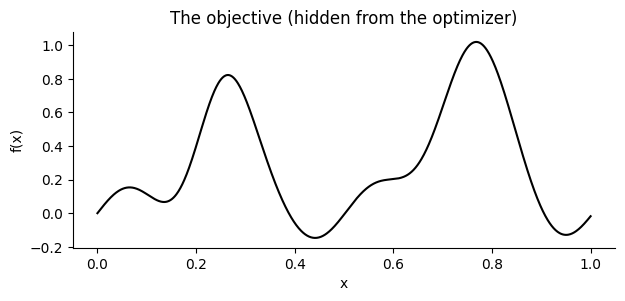

In [2]:
def f(x):
    # The unknown objective on [0, 1]. BO may only call it, never look inside.
    x = np.asarray(x, dtype=float)
    return 0.8 * np.exp(-((x - 0.25) / 0.08) ** 2) + np.exp(-((x - 0.75) / 0.1) ** 2) + 0.15 * np.sin(25 * x)

grid = np.linspace(0.0, 1.0, 1001)          # where we will evaluate the surrogate and the acquisition
f_max = f(grid).max()
print(f"true maximum {f_max:.3f} at x = {grid[np.argmax(f(grid))]:.3f}")

plt.figure(figsize=(7, 2.8))
plt.plot(grid, f(grid), "k")
plt.xlabel("x"); plt.ylabel("f(x)"); plt.title("The objective (hidden from the optimizer)")
plt.show()

## 2. One step, slowly

Start with three random evaluations. We then fit a GP (a Gaussian process is a distribution over functions; `GPScratch` is OpenBO's small NumPy implementation) and ask it, for every `x` on the grid, for a predictive **mean** and **variance**.

The acquisition function we use is **expected improvement (EI)**: how much better than the best value seen so far do we *expect* a new point to be, averaged over the GP's uncertainty? A point scores high when its mean is high (exploitation) or its variance is large (exploration). `expected_improvement_maximization(mean, variance, best_y)` computes it in closed form.

next point to evaluate: 0.724


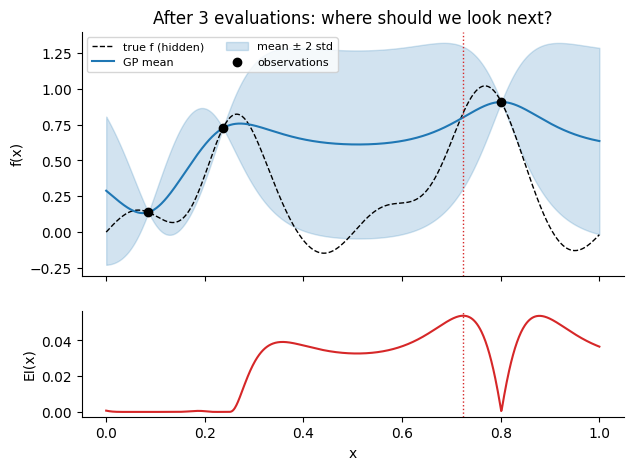

In [3]:
rng = np.random.default_rng(3)
x_obs = rng.uniform(0.0, 1.0, size=3)
y_obs = f(x_obs)

# A Matern-5/2 GP with a fixed lengthscale of 0.1 (about "how far apart two inputs must be before their values are unrelated").
gp = GPScratch(lengthscale=0.1, variance=1.0, noise=1e-6, kernel_type="matern52")
gp.fit(x_obs[:, None], y_obs)                       # GPScratch wants inputs of shape (n, d)

mean, var = gp.posterior(grid[:, None])             # predictive mean and variance on the grid
std = np.sqrt(var)
ei = expected_improvement_maximization(mean, var, best_y=y_obs.max())
x_next = grid[np.argmax(ei)]
print("next point to evaluate:", round(float(x_next), 3))

def plot_state(x_obs, y_obs, mean, std, ei, x_next, title=""):
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
    a1.plot(grid, f(grid), "k--", lw=1, label="true f (hidden)")
    a1.plot(grid, mean, color="C0", label="GP mean")
    a1.fill_between(grid, mean - 2 * std, mean + 2 * std, color="C0", alpha=0.2, label="mean ± 2 std")
    a1.scatter(x_obs, y_obs, c="k", zorder=5, label="observations")
    a1.axvline(x_next, color="C3", lw=1, ls=":")
    a1.set_ylabel("f(x)"); a1.set_title(title); a1.legend(loc="upper left", fontsize=8, ncol=2)
    a2.plot(grid, ei, color="C3"); a2.axvline(x_next, color="C3", lw=1, ls=":")
    a2.set_ylabel("EI(x)"); a2.set_xlabel("x")
    plt.show()

plot_state(x_obs, y_obs, mean, std, ei, x_next, title="After 3 evaluations: where should we look next?")

**Why a fixed lengthscale?** The GP has hyperparameters (the lengthscale and the signal variance). `GPScratch` can fit them by maximizing the marginal likelihood (`optimize_hyperparameters=True`), and OpenBO does that by default on real problems, but with only a handful of points that fit is unreliable: try it here and you will see the lengthscale collapse to almost zero and the posterior turn into spikes at the observations. Notebook 02 shows why. For this toy we fix the lengthscale at 0.1, a sensible value for a function that varies on that scale.

Read the top panel as the optimizer's belief: the blue band is wide where we have no data and pinches to zero at the observations. The bottom panel is the acquisition function, and the dotted red line marks its maximum, the next point we will evaluate. Notice that it is *not* simply where the mean is highest: unexplored regions with high uncertainty compete with promising regions.

## 3. The whole loop

Wrap the three steps in a function. We refit the GP (same fixed hyperparameters, new data) at every iteration and keep a snapshot of each state so that we can plot it afterwards.

In [4]:
def bayes_opt_1d(f, x_init, n_iter):
    x_obs, y_obs = np.array(x_init, dtype=float), f(np.array(x_init, dtype=float))
    snapshots = []
    for it in range(n_iter):
        gp = GPScratch(lengthscale=0.1, variance=1.0, noise=1e-6, kernel_type="matern52")
        gp.fit(x_obs[:, None], y_obs)                                  # 1. fit
        mean, var = gp.posterior(grid[:, None])
        ei = expected_improvement_maximization(mean, var, y_obs.max()) # 2. score
        x_next = grid[np.argmax(ei)]
        snapshots.append((x_obs.copy(), y_obs.copy(), mean, np.sqrt(var), ei, x_next))
        x_obs = np.append(x_obs, x_next)                               # 3. evaluate and record
        y_obs = np.append(y_obs, f(x_next))
    return x_obs, y_obs, snapshots

x_all, y_all, snapshots = bayes_opt_1d(f, x_obs, n_iter=10)
print("best value found:", round(float(y_all.max()), 4), "at x =", round(float(x_all[np.argmax(y_all)]), 3), f"(true max {f_max:.4f})")

best value found: 1.0196 at x = 0.768 (true max 1.0196)


Here are the states after 1, 3, 6 and 10 loop iterations.

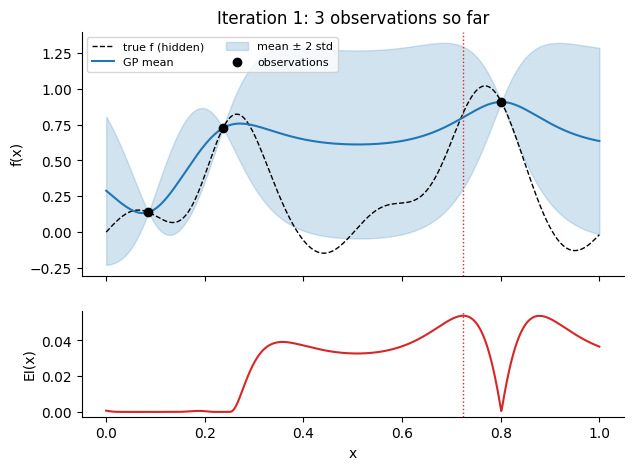

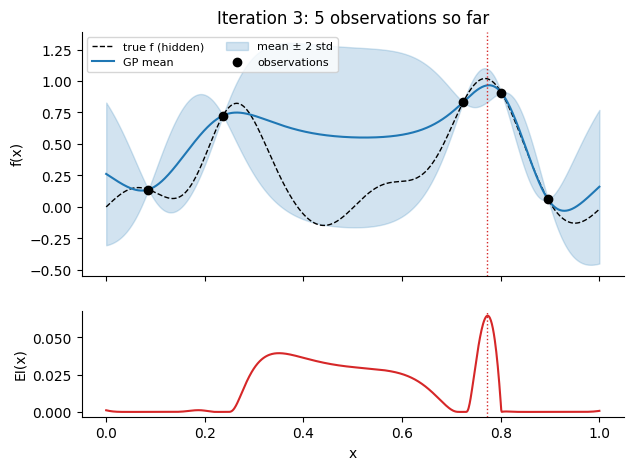

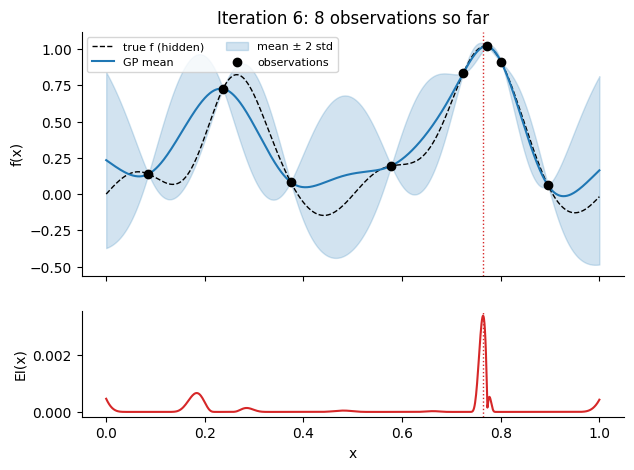

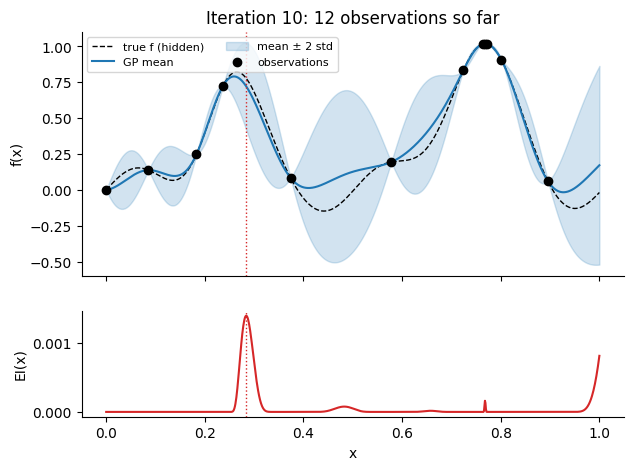

In [5]:
for it in (0, 2, 5, 9):
    xo, yo, m, s, e, xn = snapshots[it]
    plot_state(xo, yo, m, s, e, xn, title=f"Iteration {it + 1}: {len(xo)} observations so far")

What to look for: the three initial points already touched both peaks, so the GP knows both are high. In the next evaluations EI spends points on the right-hand peak, which looks higher, and by iteration 6 the acquisition function is almost zero everywhere except a narrow spike next to the best point: the optimizer is now refining. The band stays wide in places with no data (for example between 0.4 and 0.6), but the GP judges them unlikely to beat what we already have. No gradient was needed, and only 13 evaluations were spent in total.

## 4. Is it better than guessing?

The honest comparison is **random search** with the same budget. One run can be lucky, so we repeat both methods over 20 random starting designs and plot the average best value found after each evaluation (higher is better).

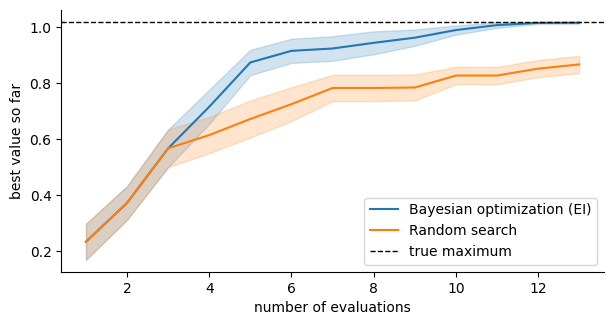

mean gap to the optimum after 13 evaluations: BO 0.004, random 0.152


In [6]:
n_total, n_runs = 13, 20            # 3 initial points + 10 BO iterations = 13 evaluations
bo_curves, rs_curves = [], []
for seed in range(n_runs):
    r = np.random.default_rng(100 + seed)
    x0 = r.uniform(0.0, 1.0, size=3)
    xb, yb, _ = bayes_opt_1d(f, x0, n_iter=n_total - 3)
    bo_curves.append(np.maximum.accumulate(yb))
    xr = np.concatenate([x0, r.uniform(0.0, 1.0, size=n_total - 3)])   # same 3 starting points, then random
    rs_curves.append(np.maximum.accumulate(f(xr)))

bo_curves, rs_curves = np.array(bo_curves), np.array(rs_curves)
evals = np.arange(1, n_total + 1)
plt.figure(figsize=(7, 3.4))
for curves, name, c in ((bo_curves, "Bayesian optimization (EI)", "C0"), (rs_curves, "Random search", "C1")):
    mu, se = curves.mean(0), curves.std(0) / np.sqrt(n_runs)
    plt.plot(evals, mu, color=c, label=name); plt.fill_between(evals, mu - se, mu + se, color=c, alpha=0.2)
plt.axhline(f_max, color="k", ls="--", lw=1, label="true maximum")
plt.xlabel("number of evaluations"); plt.ylabel("best value so far"); plt.legend(); plt.show()
print(f"mean gap to the optimum after {n_total} evaluations: BO {f_max - bo_curves[:, -1].mean():.3f}, random {f_max - rs_curves[:, -1].mean():.3f}")

## 5. The same thing with OpenBO's implementation, on a 2D benchmark

You have just written what `openbo.optimizers.bo_scratch.run_bo_scratch` does, with two additions that matter in practice: the next point is found by a **multistart search** (a pool of Sobol points refined with L-BFGS-B) instead of a grid, so it scales beyond one dimension, and it supports several kernels and search strategies.

We run it on the **Branin** function, a standard 2D benchmark. As in all of OpenBO it is implemented in maximization form (the negative of the textbook function), so its maximum is `-0.398`. `get_function_spec` returns the objective, its bounds and its known optimum.

In [7]:
from openbo.optimizers.bo_scratch import run_bo_scratch
from openbo.test_functions.registry import get_function_spec

spec = get_function_spec("branin")
print("bounds:", spec.bounds, "| optimum:", round(spec.optimum, 4))

result = run_bo_scratch(spec.objective, spec.bounds, n_init=5, n_iter=25, seed=0)
print("evaluations:", result.y_obs.shape[0], "| best value:", round(float(result.y_obs.max()), 4))

bounds: [(0.0, 1.0), (0.0, 1.0)] | optimum: -0.3979


evaluations: 30 | best value: -0.3981


The objective takes an array of shape `(n, 2)` and returns `(n,)`. Let us compare against random search over 5 seeds, using the regret convention from the top of the notebook (the best value so far, as a gap to the known optimum, on a log scale).

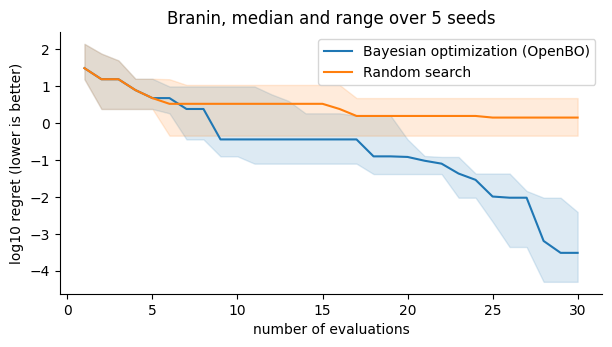

median log10 regret after 30 evaluations: BO -3.52 | random 0.14


In [8]:
def log_regret(y_obs, optimum):
    return np.log10(np.maximum(optimum - np.maximum.accumulate(y_obs), 1e-12))

n_evals, n_seeds = 30, 5
bo_regret, rs_regret = [], []
for seed in range(n_seeds):
    res = run_bo_scratch(spec.objective, spec.bounds, n_init=5, n_iter=n_evals - 5, seed=seed)
    bo_regret.append(log_regret(res.y_obs, spec.optimum))
    points = np.random.default_rng(seed).random((n_evals, 2))          # inputs live in [0, 1]^2
    rs_regret.append(log_regret(spec.objective(points), spec.optimum))

evals = np.arange(1, n_evals + 1)
plt.figure(figsize=(7, 3.4))
for curves, name, c in ((bo_regret, "Bayesian optimization (OpenBO)", "C0"), (rs_regret, "Random search", "C1")):
    arr = np.array(curves)
    plt.plot(evals, np.median(arr, 0), color=c, label=name)
    plt.fill_between(evals, arr.min(0), arr.max(0), color=c, alpha=0.15)
plt.xlabel("number of evaluations"); plt.ylabel("log10 regret (lower is better)")
plt.title("Branin, median and range over 5 seeds"); plt.legend(); plt.show()
print("median log10 regret after 30 evaluations: BO", round(float(np.median([c[-1] for c in bo_regret])), 2),
      "| random", round(float(np.median([c[-1] for c in rs_regret])), 2))

## Takeaways

- BO replaces "try many points" with "model what we know, then pick the most informative point".
- Two ingredients matter: the **surrogate** (how well it captures `f`, and how honest its uncertainty is) and the **acquisition function** (how it trades off exploring against exploiting).
- It pays off when evaluations are expensive: in the experiments above BO pulled ahead of random search after about 4 evaluations on the 1D toy and after about 9 on Branin, and with a budget of 30 on Branin it was far ahead (median log10 regret about -3.5 against about +0.1, 5 seeds).

**Things to know about the OpenBO implementation**
- `GPScratch` needs at least two distinct observations to give meaningful uncertainty (with one observation its standardization degenerates). That is why every example starts with several initial points (`n_init`).
- It assumes (almost) noise-free evaluations by default (`noise=1e-6`). For noisy objectives pass a larger `noise`.

**Next:** `02_gp_posterior_visualized` opens the surrogate box (kernels, lengthscales, hyperparameter fitting); `03_ei_ucb_pi` compares acquisition functions.